# Kobe Etkisi: NBA Yıldızları Bebek İsimlerini Değiştiriyor mu?

**Araştırma sorusu:** Bir NBA oyuncusu draft edildiğinde, şampiyon olduğunda, MVP seçildiğinde ya da hayatını kaybettiğinde, ABD'de o oyuncunun ismini alan bebek sayısı artıyor mu?

**Veri:**
- **Bebek isimleri:** ABD Sosyal Güvenlik Kurumu (SSA) *Baby Names from Social Security Card Applications – National Data*, 1880–2024. Her satır: isim, cinsiyet, o yıl bu isimle kayıt edilen bebek sayısı. Gizlilik için 5'ten az kullanılan isimler veride yok. Ham dosyalar SSA'nın `names.zip` arşivinden, GitHub'daki [dxdc/babynames](https://github.com/dxdc/babynames) aynası üzerinden alındı ve `data/names_all.csv.gz` olarak birleştirildi.
- **NBA olayları:** Draft, şampiyonluk, MVP ve vefat yılları elle derlendi (kaynak: Basketball-Reference).

**Yöntem:**
1. Sayıları o yılın toplam erkek doğumlarına bölerek **milyonda pay** (per million) hesapla. Böylece doğum sayısındaki yıllık değişimler sonucu etkilemez.
2. İsim eğrilerini olay yıllarıyla birlikte çiz (EDA).
3. **Event study (olay çalışması):** Her olay için olaydan önceki 2 yıl ile olay yılı ve sonraki yılın ortalama payını karşılaştır.
4. **Placebo testi:** Aynı hesabı NBA'le ilgisi olmayan binlerce isim için de yap. Bir olaydan sonraki artış, sıradan isimlerin yıllık dalgalanmalarına göre ne kadar sıra dışı?
5. Karıştırıcı faktörleri (confounder) incele: artış gerçekten oyuncudan mı geliyor?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
NAVY, GRAY, RED = "#1F4E79", "#9E9E9E", "#C62828"

names = pd.read_csv("data/names_all.csv.gz")
print(names.shape, "| yıllar:", names["year"].min(), "-", names["year"].max())

# Sadece erkek isimleri (incelediğimiz oyuncuların hepsi erkek)
male = names[names["sex"] == "M"]
total = male.groupby("year")["count"].sum()

# isim x yıl tablosu: sayı ve milyonda pay
counts = male.pivot_table(index="name", columns="year", values="count", fill_value=0)
share = counts.div(total, axis=1) * 1e6
print(counts.shape[0], "farklı erkek ismi")

(2149477, 4) | yıllar: 1880 - 2024


44904 farklı erkek ismi


## 1. NBA olayları

Analize sadece **ayırt edici** isimleri aldım. "Kevin" (Durant) ya da "Michael" (Jordan) gibi çok yaygın isimlerde oyuncunun etkisini ayırmak imkânsız. İstisna olarak "Jordan" (soyad olarak isim) ve "Stephen" karşılaştırma için tabloda.

**Not:** NBA Finalleri haziranda oynanıyor. Bu yüzden bir şampiyonluğun etkisi hem o yılın ikinci yarısında hem de sonraki yılda görülebilir. Analizde "sonra" dönemi olay yılı ile sonraki yılın ortalaması olarak alındı.

In [2]:
events = pd.DataFrame([
    ("Kobe", "Kobe Bryant", 1996, "Draft"), ("Kobe", "Kobe Bryant", 2000, "Şampiyonluk"),
    ("Kobe", "Kobe Bryant", 2008, "MVP"), ("Kobe", "Kobe Bryant", 2009, "Şampiyonluk"),
    ("Kobe", "Kobe Bryant", 2020, "Vefat"),
    ("Shaquille", "Shaquille O'Neal", 1992, "Draft"), ("Shaquille", "Shaquille O'Neal", 2000, "Şampiyonluk"),
    ("Lebron", "LeBron James", 2003, "Draft"), ("Lebron", "LeBron James", 2012, "Şampiyonluk"),
    ("Lebron", "LeBron James", 2016, "Şampiyonluk"),
    ("Kyrie", "Kyrie Irving", 2011, "Draft"), ("Kyrie", "Kyrie Irving", 2016, "Şampiyonluk"),
    ("Giannis", "Giannis Antetokounmpo", 2019, "MVP"), ("Giannis", "Giannis Antetokounmpo", 2021, "Şampiyonluk"),
    ("Kawhi", "Kawhi Leonard", 2014, "Şampiyonluk"), ("Kawhi", "Kawhi Leonard", 2019, "Şampiyonluk"),
    ("Iverson", "Allen Iverson", 1996, "Draft"), ("Iverson", "Allen Iverson", 2001, "MVP"),
    ("Klay", "Klay Thompson", 2015, "Şampiyonluk"),
    ("Tatum", "Jayson Tatum", 2017, "Draft"), ("Tatum", "Jayson Tatum", 2024, "Şampiyonluk"),
    ("Hakeem", "Hakeem Olajuwon", 1994, "Şampiyonluk"), ("Dirk", "Dirk Nowitzki", 2011, "Şampiyonluk"),
    ("Nikola", "Nikola Jokić", 2021, "MVP"), ("Nikola", "Nikola Jokić", 2023, "Şampiyonluk"),
    ("Luka", "Luka Dončić", 2018, "Draft"), ("Zion", "Zion Williamson", 2019, "Draft"),
    ("Stephen", "Stephen Curry", 2015, "Şampiyonluk"), ("Jordan", "Michael Jordan", 1991, "Şampiyonluk"),
], columns=["isim", "oyuncu", "yil", "olay"])
events

,isim,oyuncu,yil,olay
0,Kobe,Kobe Bryant,1996,Draft
1,Kobe,Kobe Bryant,2000,Şampiyonluk
2,Kobe,Kobe Bryant,2008,MVP
3,Kobe,Kobe Bryant,2009,Şampiyonluk
4,Kobe,Kobe Bryant,2020,Vefat
5,Shaquille,Shaquille O'Neal,1992,Draft
6,Shaquille,Shaquille O'Neal,2000,Şampiyonluk
7,Lebron,LeBron James,2003,Draft
8,Lebron,LeBron James,2012,Şampiyonluk
9,Lebron,LeBron James,2016,Şampiyonluk


## 2. Kobe Etkisi

Projenin adını veren isim. Kobe ismi SSA verisinde ilk kez 1989'da görünüyor.

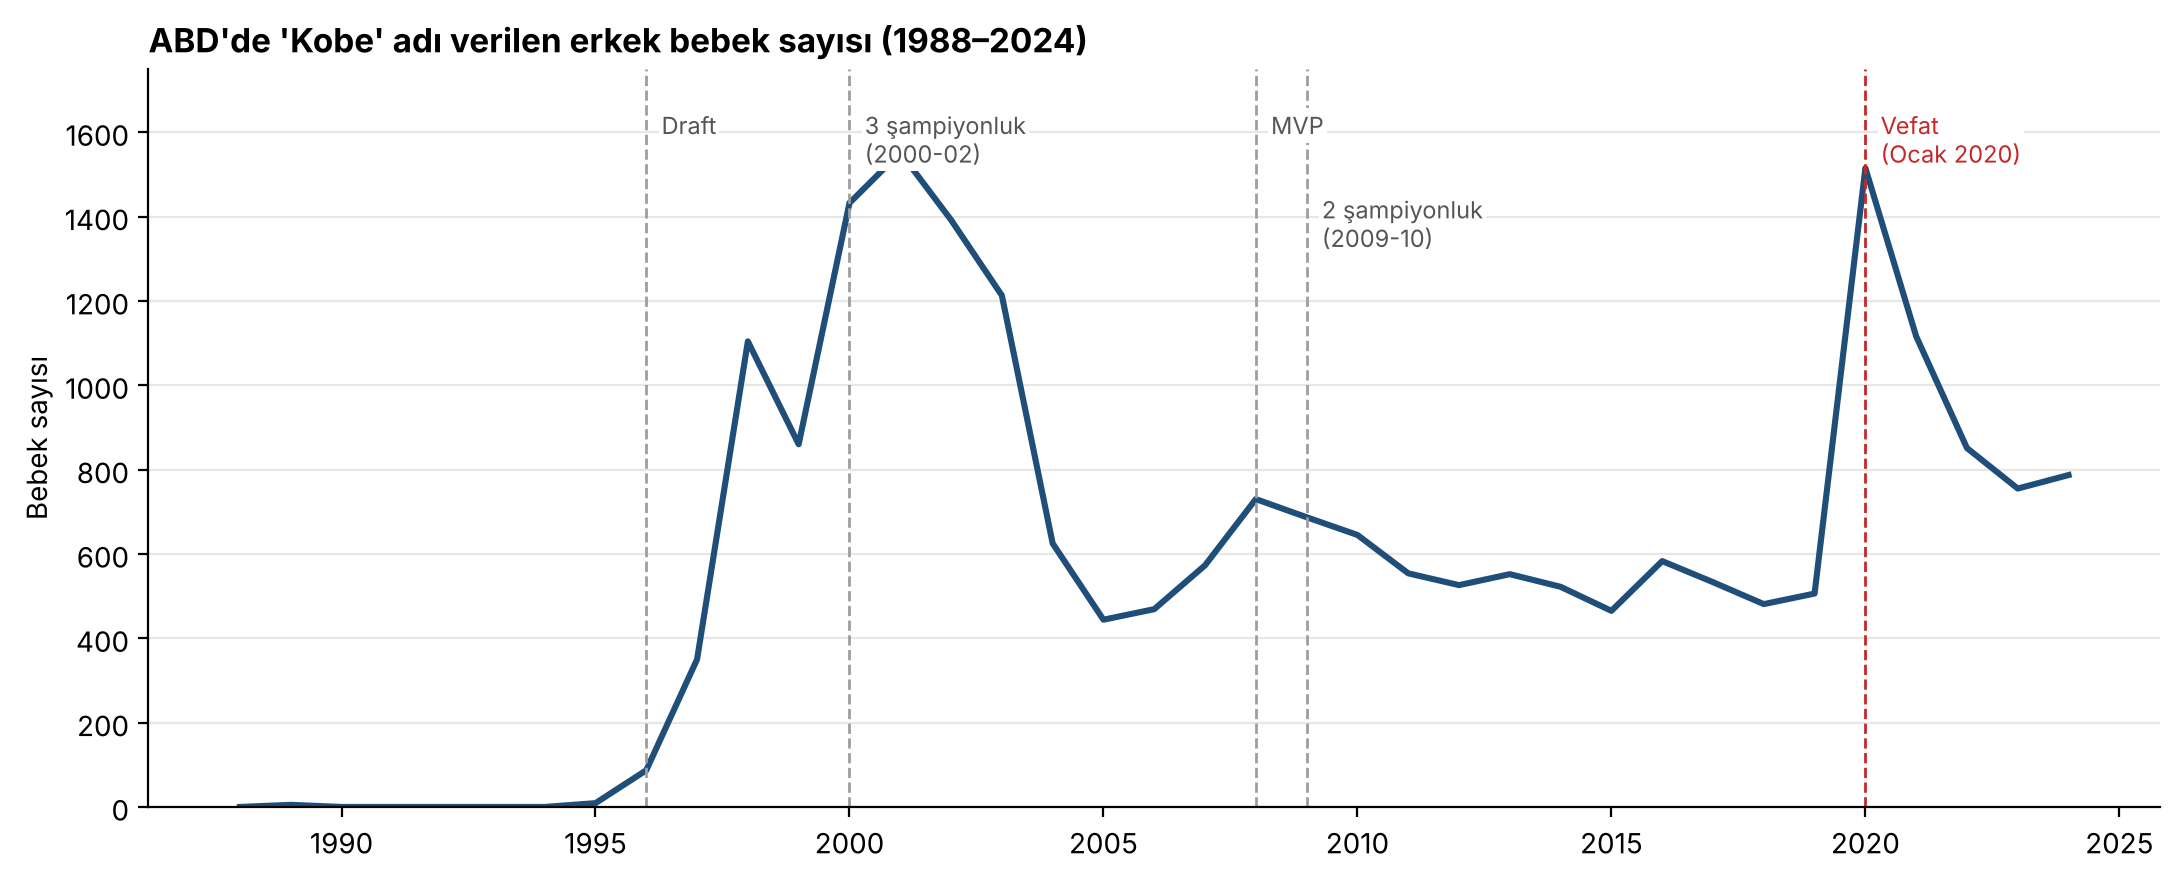

{1995: 9, 1996: 87, 1997: 350, 1998: 1104, 2001: 1552, 2019: 506, 2020: 1515, 2021: 1116, 2024: 787}


In [3]:
k = counts.loc["Kobe"]
fig, ax = plt.subplots(figsize=(11, 4.5))
yrs = range(1988, 2025)
ax.plot(list(yrs), [k.get(y, 0) for y in yrs], color=NAVY, lw=2.2)
marks = {1996: "Draft", 2000: "3 şampiyonluk\n(2000-02)", 2008: "MVP", 2009: "2 şampiyonluk\n(2009-10)", 2020: "Vefat\n(Ocak 2020)"}
ypos = {1996: 1650, 2000: 1650, 2008: 1650, 2009: 1450, 2020: 1650}
for y, t in marks.items():
    ax.axvline(y, color=RED if y == 2020 else GRAY, ls="--", lw=1)
    ax.text(y + 0.3, ypos[y], t, fontsize=8.5, color=RED if y == 2020 else "#555", va="top",
            bbox=dict(fc="white", ec="none", pad=1))
ax.set_title("ABD'de 'Kobe' adı verilen erkek bebek sayısı (1988–2024)", loc="left", fontweight="bold")
ax.set_ylabel("Bebek sayısı"); ax.set_ylim(0, 1750); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("images/kobe_trend.png", dpi=200); plt.show()

print({y: int(k.get(y, 0)) for y in [1995, 1996, 1997, 1998, 2001, 2019, 2020, 2021, 2024]})

### Bulgu 1: Kobe ismi iki kez patladı

- **Draft (1996) sonrası:** 1995'te 9 bebek, 1998'de 1.104, 2001'de 1.552 (zirve, üst üste üç şampiyonluk döneminde).
- **Vefat (Ocak 2020) sonrası:** 2019'da 506 bebek, 2020'de 1.515. Tek yılda **3 kat** artış, ilk zirveyle neredeyse aynı seviye.
- 2009-10 şampiyonlukları ise belirgin bir artış yaratmamış.

İlk dikkat çeken şey: en büyük etkiyi şampiyonluklar değil, **oyuncunun sahneye çıkışı ve vefatı** yaratmış. Bu gözlemi aşağıda bütün oyuncular için test ediyorum.

## 3. Diğer oyuncular

Her grafikte isim payı (milyonda) ve olay yılları (dikey çizgiler) var.

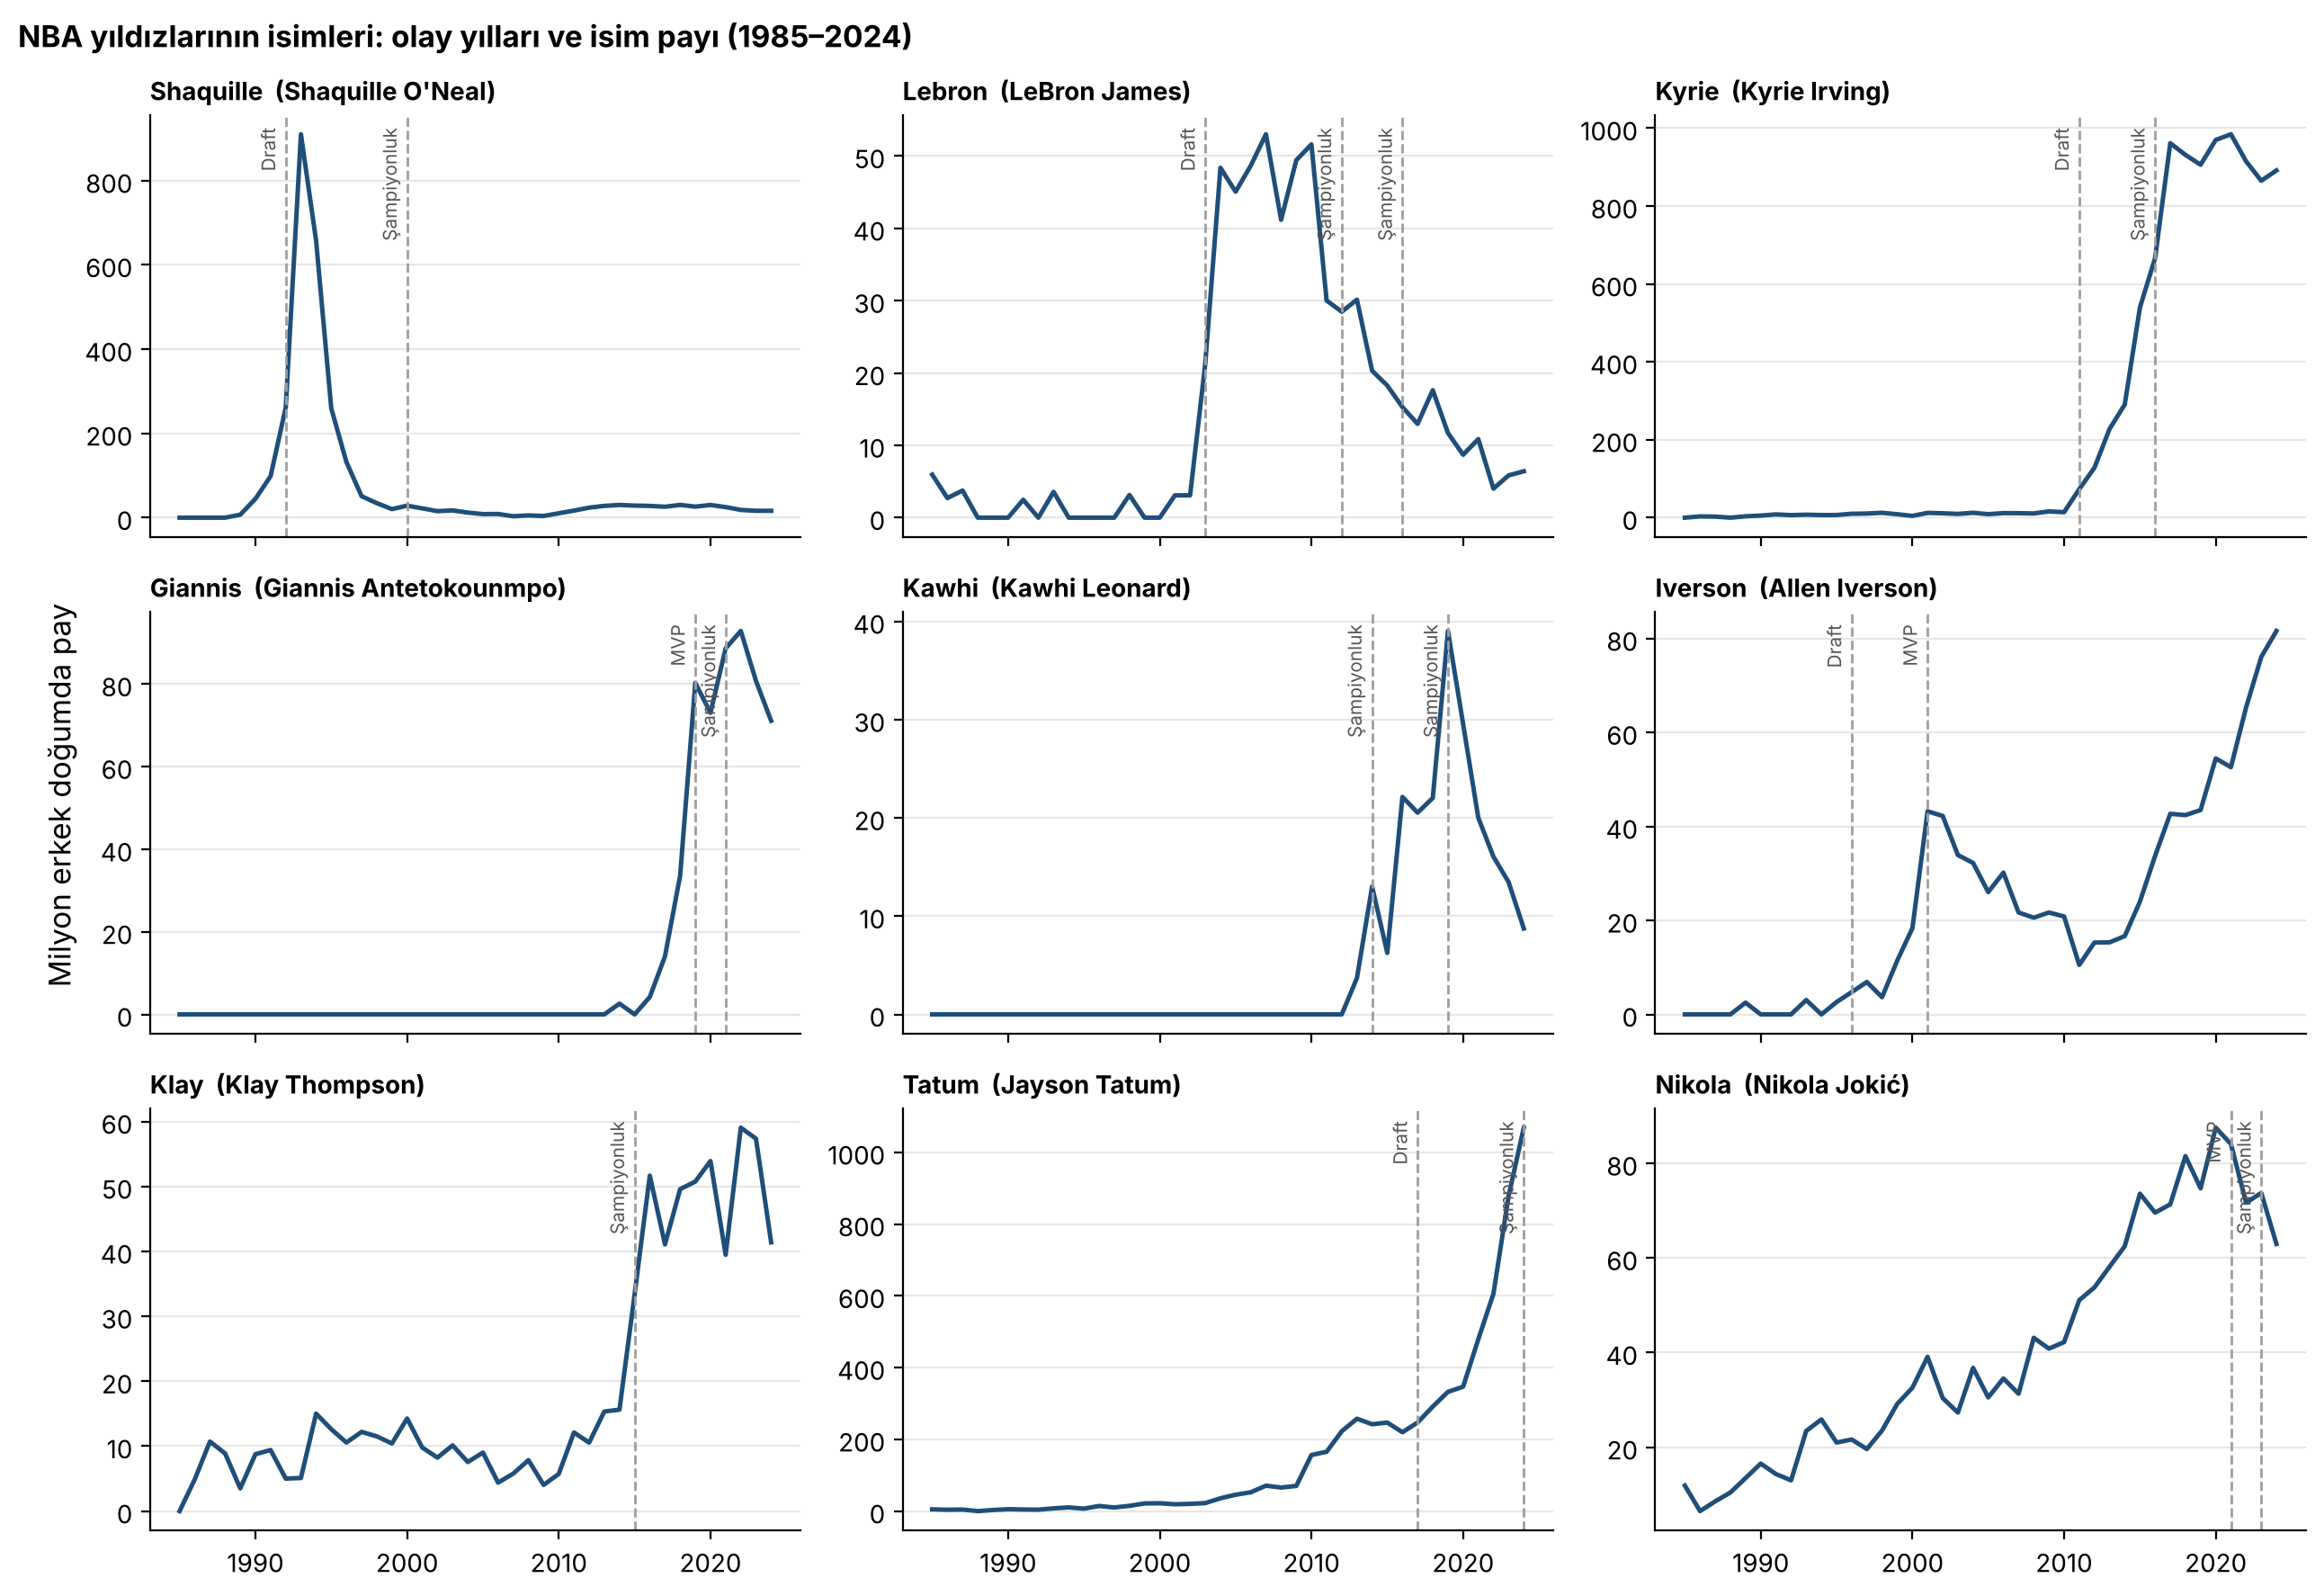

In [4]:
show = ["Shaquille", "Lebron", "Kyrie", "Giannis", "Kawhi", "Iverson", "Klay", "Tatum", "Nikola"]
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for ax, n in zip(axes.flat, show):
    s = share.loc[n, 1985:2024]
    ax.plot(s.index, s.values, color=NAVY, lw=1.8)
    for _, r in events[events.isim == n].iterrows():
        ax.axvline(r.yil, color=RED if r.olay == "Vefat" else GRAY, ls="--", lw=1)
        ax.text(r.yil - 0.4, 0.97, r.olay, fontsize=7.5, color="#555", va="top", ha="right", rotation=90,
                transform=ax.get_xaxis_transform())
    ax.set_title(f"{n}  ({events[events.isim == n].oyuncu.iloc[0]})", loc="left", fontsize=10, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
fig.supylabel("Milyon erkek doğumda pay")
fig.suptitle("NBA yıldızlarının isimleri: olay yılları ve isim payı (1985–2024)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig("images/small_multiples.png", dpi=200); plt.show()

## 4. Event study ve placebo testi

Grafiklere bakarak "artmış" demek kolay, ama isimler zaten her yıl dalgalanıyor. Bir artışın **sıra dışı** olup olmadığını anlamak için bir karşılaştırma lazım.

**Ölçü:** Her olay için
- **Önce:** olaydan önceki 2 yılın ortalama payı (E-2, E-1)
- **Sonra:** olay yılı ve sonraki yılın ortalama payı (E, E+1)
- **Değişim:** sonra / önce (kat)

**Placebo:** 1985–2023 arasındaki her yıl için, NBA listesinde olmayan ve "önce" döneminde benzer büyüklükte (bebek sayısı yarısı ile iki katı arası) olan bütün isimlerin aynı değişimini hesapla. Sonra her olayın değişimini bu dağılımda bir **yüzdelik dilime** yerleştir. Örneğin 99. yüzdelik, "aynı büyüklükteki isimlerin %99'undan daha fazla artmış" demek.

Benzer büyüklük şartı önemli: küçük isimler (yılda 10-20 bebek) doğası gereği çok oynak, büyük isimler daha stabil.

In [5]:
def pre_post(table, name, E):
    s = table.loc[name]
    pre = np.mean([s.get(E - 2, 0), s.get(E - 1, 0)])
    post = np.mean([s[y] for y in (E, E + 1) if y in s.index])
    return pre, post

events[["pay_once", "pay_sonra"]] = [pre_post(share, r.isim, r.yil) for r in events.itertuples()]
events["sayi_once"] = [pre_post(counts, r.isim, r.yil)[0] for r in events.itertuples()]
events["kat"] = events.pay_sonra / events.pay_once

# Placebo dağılımı: (önceki bebek sayısı, log değişim)
nba = set(events.isim)
rows = []
for E in range(1985, 2024):
    pre_c = (counts[E - 2] + counts[E - 1]) / 2
    pre_s = (share[E - 2] + share[E - 1]) / 2
    post_s = (share[E] + share[E + 1]) / 2
    ok = (pre_c >= 5) & (~counts.index.isin(nba))
    with np.errstate(divide="ignore"):
        rows.append(pd.DataFrame({"pre_c": pre_c[ok], "lr": np.log(post_s[ok] / pre_s[ok])}))
placebo = pd.concat(rows)  # log(0) olan satırlar aşağıda atılıyor
placebo = placebo[np.isfinite(placebo.lr)]
print(f"Placebo: {len(placebo):,} isim-yıl gözlemi")

def percentile(row):
    band = placebo[placebo.pre_c.between(row.sayi_once / 2, row.sayi_once * 2)]
    return (band.lr < np.log(row.kat)).mean() * 100, len(band)

events[["yuzdelik", "placebo_n"]] = [percentile(r) for r in events.itertuples()]
out = events[["oyuncu", "yil", "olay", "sayi_once", "kat", "yuzdelik"]].copy()
out["sayi_once"] = out.sayi_once.round(0).astype(int)
out = out.round({"kat": 2, "yuzdelik": 1})
out

Placebo: 367,599 isim-yıl gözlemi


,oyuncu,yil,olay,sayi_once,kat,yuzdelik
0,Kobe Bryant,1996,Draft,4,48.99,100.0
1,Kobe Bryant,2000,Şampiyonluk,982,1.49,95.7
2,Kobe Bryant,2008,MVP,521,1.40,93.1
3,Kobe Bryant,2009,Şampiyonluk,652,1.08,68.5
4,Kobe Bryant,2020,Vefat,494,2.77,99.7
5,Shaquille O'Neal,1992,Draft,146,8.18,100.0
6,Shaquille O'Neal,2000,Şampiyonluk,52,0.92,36.8
7,LeBron James,2003,Draft,6,11.27,100.0
8,LeBron James,2012,Şampiyonluk,78,0.72,6.8
9,LeBron James,2016,Şampiyonluk,37,0.73,12.8


In [6]:
summary = events.groupby("olay").agg(olay_sayisi=("kat", "size"),
                                     medyan_kat=("kat", "median"),
                                     medyan_yuzdelik=("yuzdelik", "median"),
                                     yuzde_95_ustu=("yuzdelik", lambda x: (x >= 95).mean() * 100))
summary.round(1)

,olay_sayisi,medyan_kat,medyan_yuzdelik,yuzde_95_ustu
olay,,,,
Draft,8,5.5,99.8,75.0
MVP,4,2.1,96.4,50.0
Vefat,1,2.8,99.7,100.0
Şampiyonluk,16,1.2,84.5,31.2


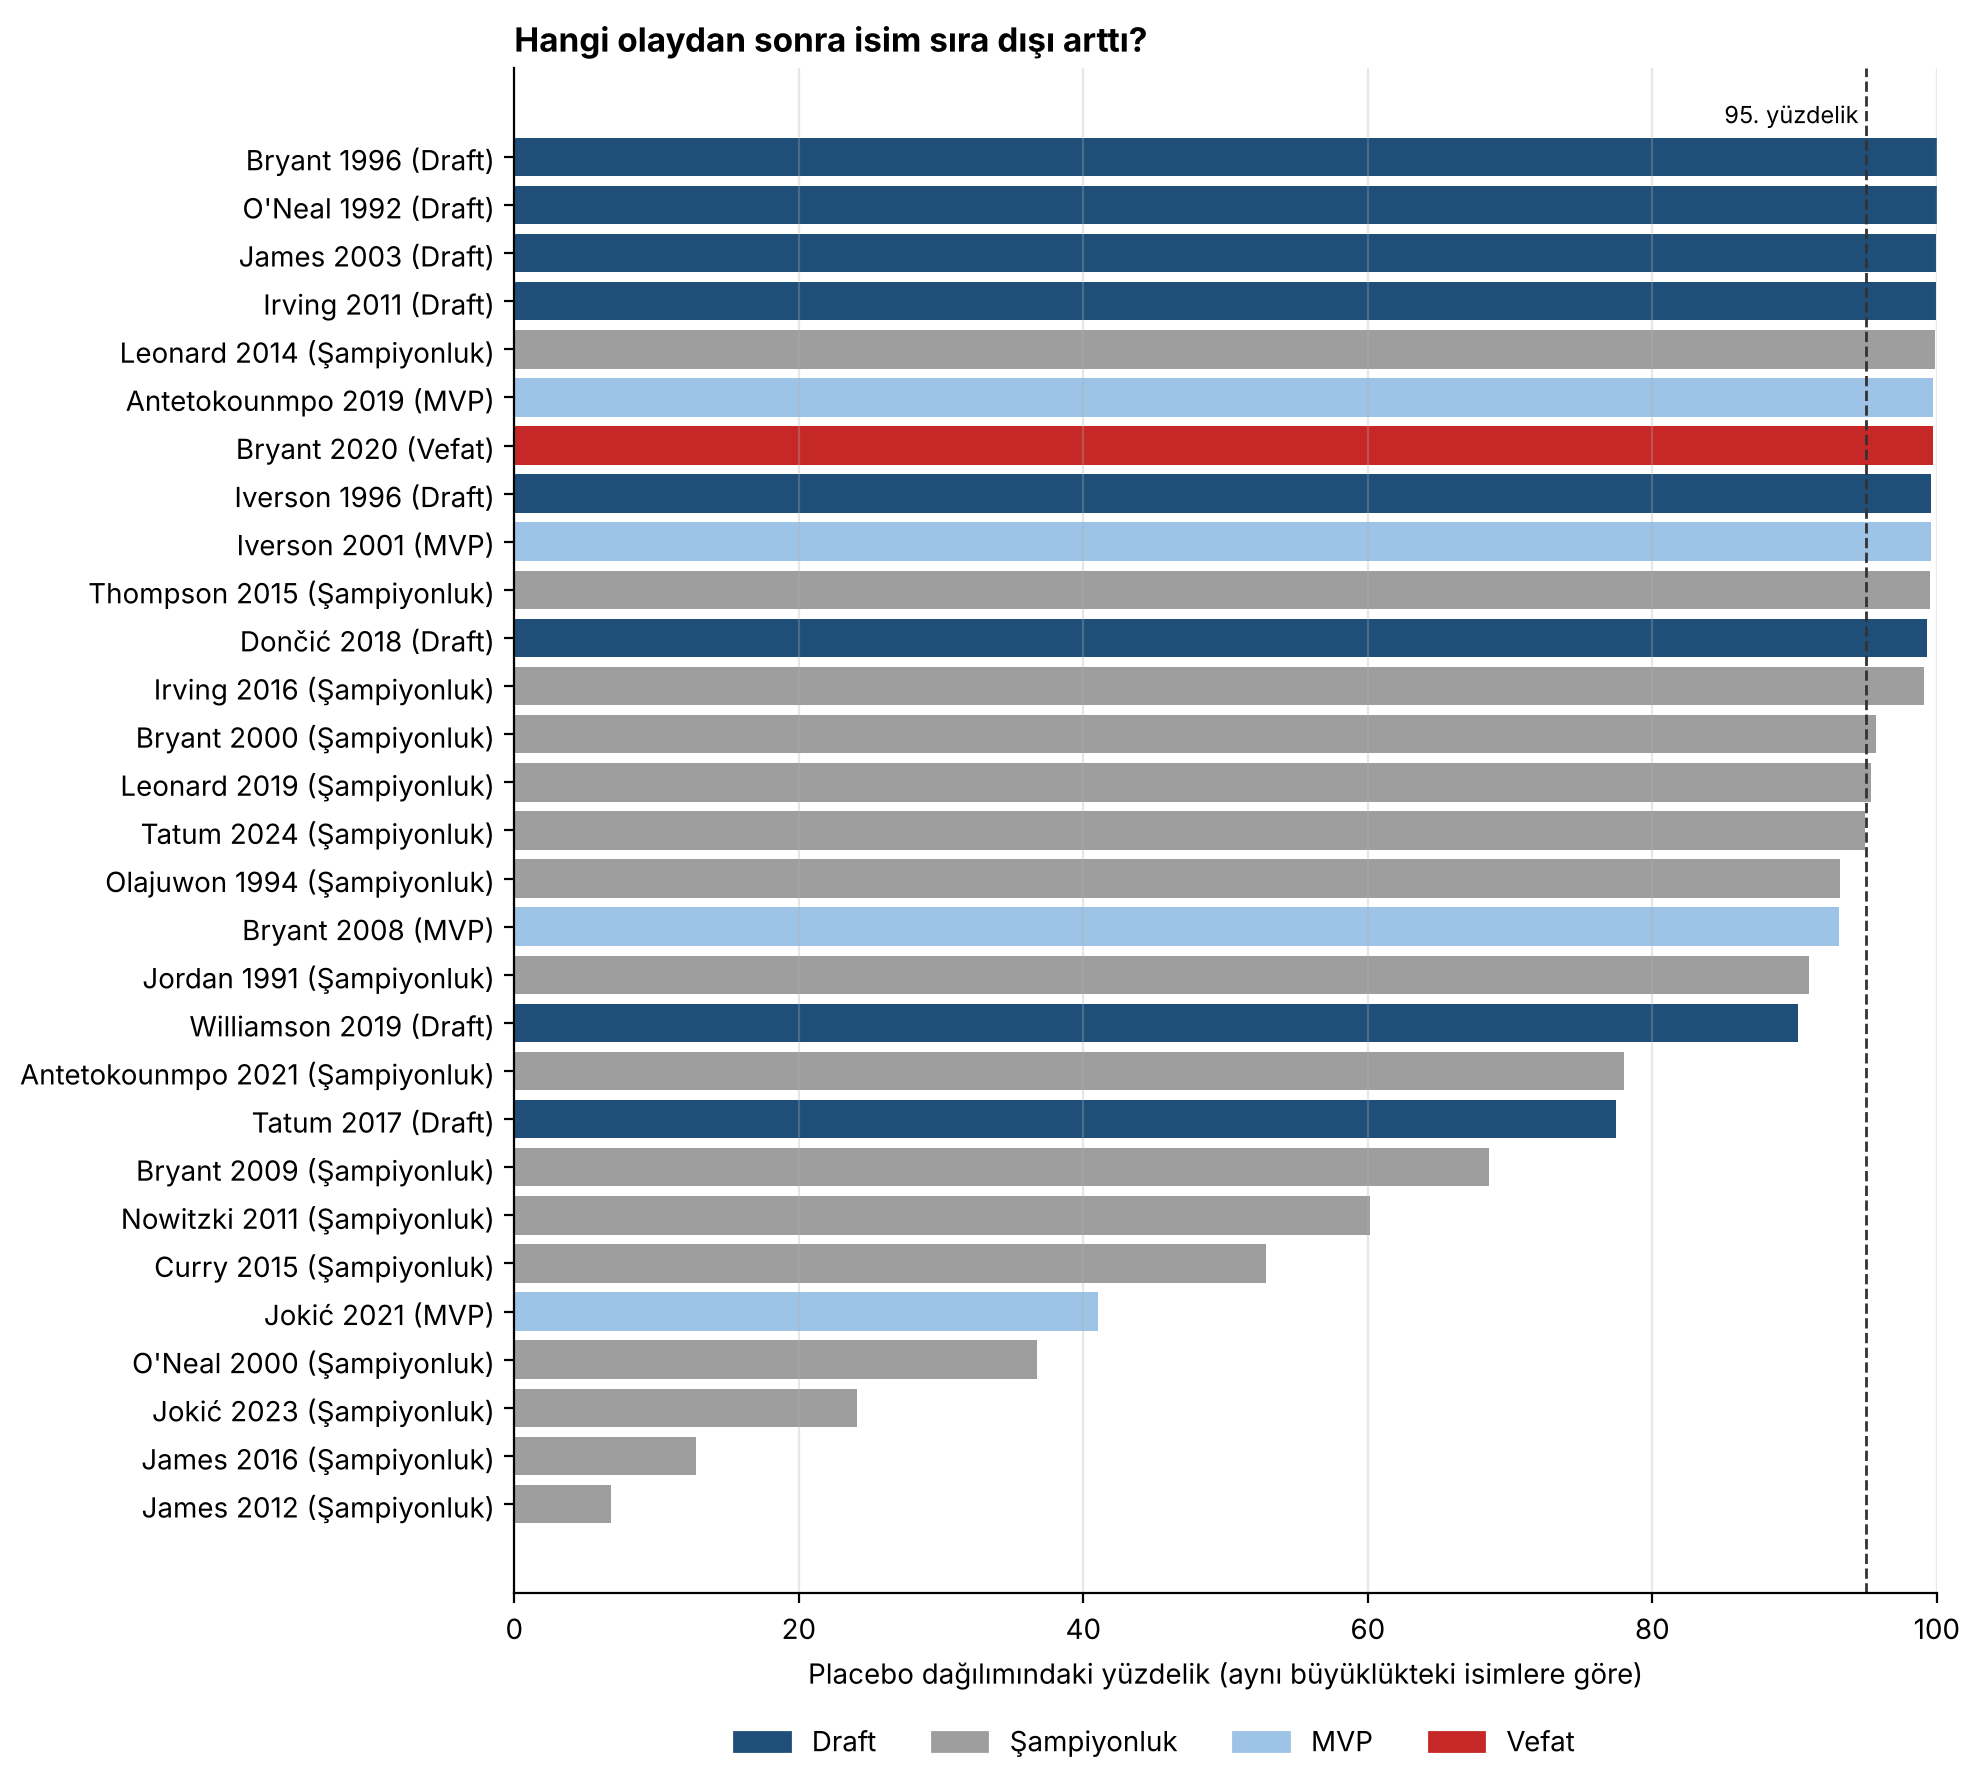

In [7]:
plot = events.sort_values("yuzdelik")
labels = plot.oyuncu.str.split().str[-1] + " " + plot.yil.astype(str) + " (" + plot.olay + ")"
colors = [NAVY if o == "Draft" else RED if o == "Vefat" else "#9DC3E6" if o == "MVP" else GRAY for o in plot.olay]
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(labels, plot.yuzdelik, color=colors)
ax.axvline(95, color="#333", ls="--", lw=1)
ax.text(94.5, len(plot) - 0.3, "95. yüzdelik", fontsize=8.5, ha="right")
ax.set_xlabel("Placebo dağılımındaki yüzdelik (aynı büyüklükteki isimlere göre)")
ax.set_title("Hangi olaydan sonra isim sıra dışı arttı?", loc="left", fontweight="bold")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=NAVY, label="Draft"), Patch(color=GRAY, label="Şampiyonluk"),
                   Patch(color="#9DC3E6", label="MVP"), Patch(color=RED, label="Vefat")],
          loc="upper center", bbox_to_anchor=(0.45, -0.07), ncol=4, frameon=False)
ax.set_xlim(0, 100); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("images/event_percentiles.png", dpi=200); plt.show()

## 5. İsmi oyuncuyla birlikte doğanlar

Bazı isimler, oyuncu ünlü olana kadar SSA verisinde hiç yok (yani yılda 5'ten az bebeğe verilmiş).

In [8]:
first = pd.DataFrame([(n, int(counts.loc[n][counts.loc[n] > 0].index.min()), int(counts.loc[n].idxmax()), int(counts.loc[n].max()))
                      for n in ["Kobe", "Giannis", "Kawhi", "Shaquille", "Kyrie", "Lebron"]],
                     columns=["isim", "ilk_gorulme", "zirve_yili", "zirve_sayisi"])
first

,isim,ilk_gorulme,zirve_yili,zirve_sayisi
0,Kobe,1989,2001,1552
1,Giannis,2014,2022,162
2,Kawhi,2013,2019,70
3,Shaquille,1989,1993,1785
4,Kyrie,1986,2017,1779
5,Lebron,1925,2007,110


## 6. Karıştırıcı faktörler: her artış oyuncudan mı?

Tablodaki bazı yüksek yüzdelikler yanıltıcı olabilir. Üç örnek:

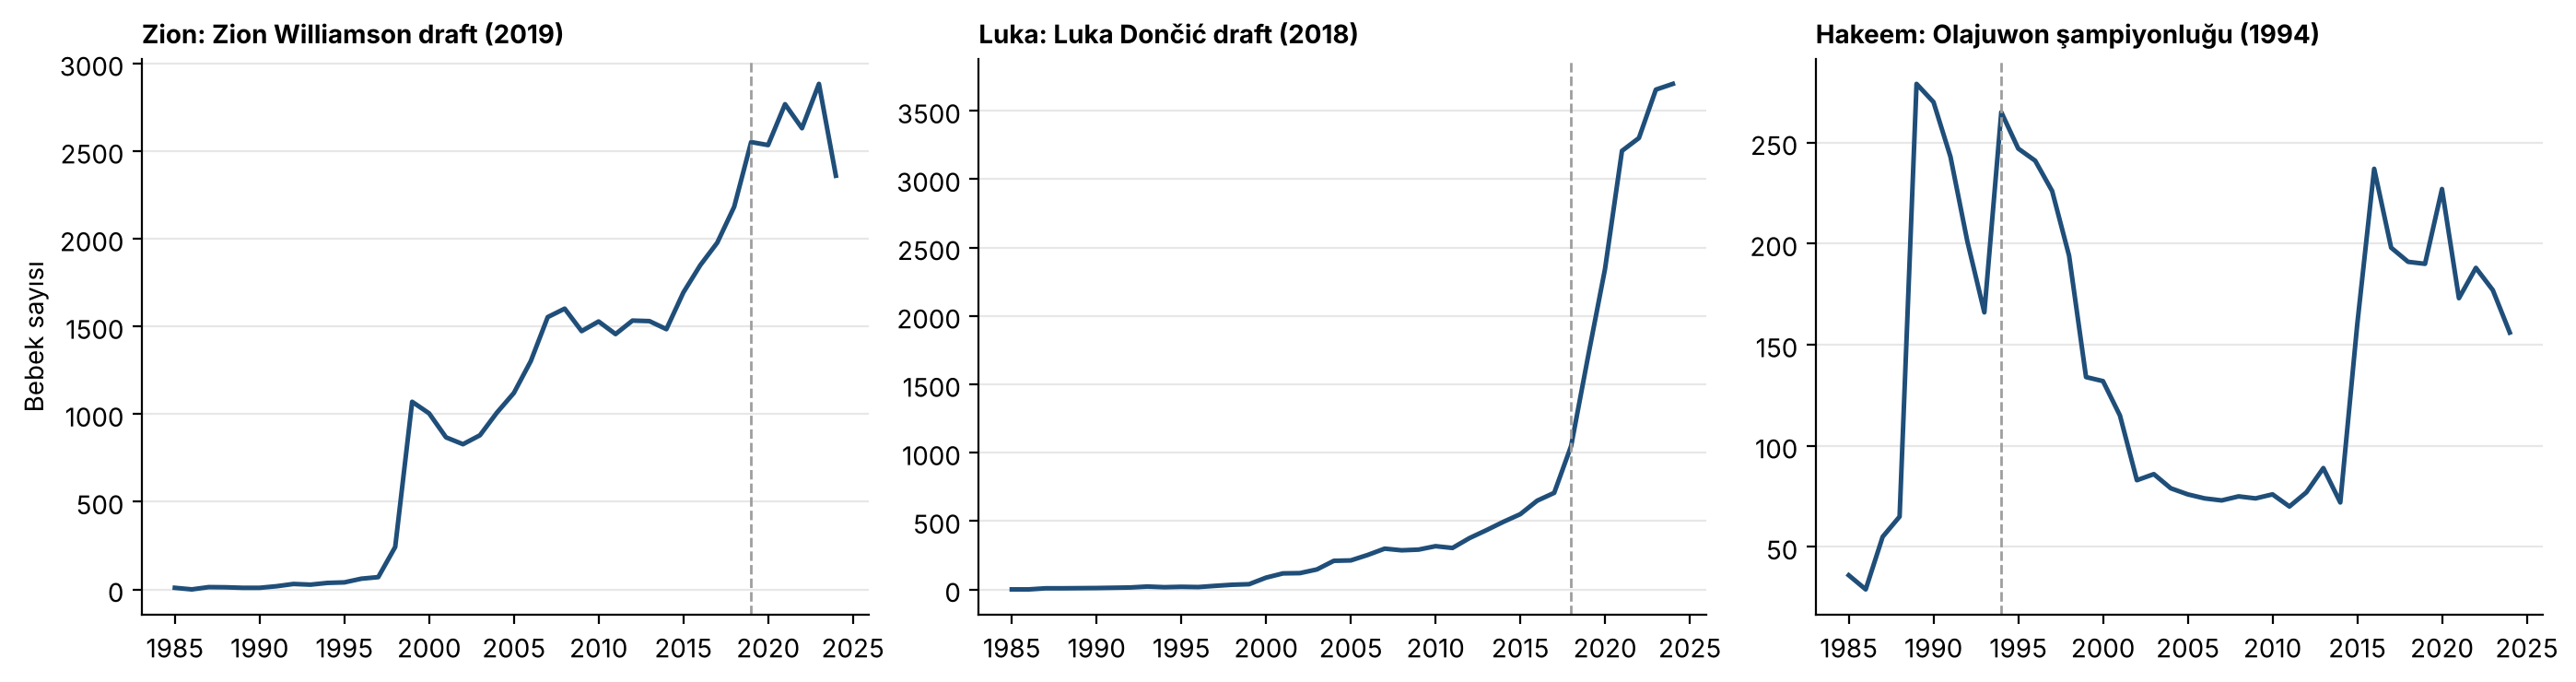

Zion 1998→1999: 242 → 1070
Hakeem 1988→1989: 65 → 279
Hakeem 2014→2016: 72 → 237
Luka 2000→2017→2024: 86 → 706 → 3697


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
cases = [("Zion", 2019, "Zion Williamson draft"), ("Luka", 2018, "Luka Dončić draft"), ("Hakeem", 1994, "Olajuwon şampiyonluğu")]
for ax, (n, y, t) in zip(axes, cases):
    s = counts.loc[n, 1985:2024]
    ax.plot(s.index, s.values, color=NAVY, lw=1.8)
    ax.axvline(y, color=GRAY, ls="--", lw=1)
    ax.set_title(f"{n}: {t} ({y})", loc="left", fontsize=10, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Bebek sayısı")
plt.tight_layout(); plt.savefig("images/confounders.png", dpi=200); plt.show()
print("Zion 1998→1999:", int(counts.loc["Zion", 1998]), "→", int(counts.loc["Zion", 1999]))
print("Hakeem 1988→1989:", int(counts.loc["Hakeem", 1988]), "→", int(counts.loc["Hakeem", 1989]))
print("Hakeem 2014→2016:", int(counts.loc["Hakeem", 2014]), "→", int(counts.loc["Hakeem", 2016]))
print("Luka 2000→2017→2024:", int(counts.loc["Luka", 2000]), "→", int(counts.loc["Luka", 2017]), "→", int(counts.loc["Luka", 2024]))

- **Zion:** İsmin asıl patlaması **1999**'da (242'den 1.070'e). Zion Williamson o yıl henüz doğmamıştı bile (2000 doğumlu). Bu sıçramanın NBA'le ilgisi yok; muhtemel bir açıklama aynı yıl vizyona giren *The Matrix* filmindeki "Zion" şehri, ama bu veriyle test edilemez. 2019'daki draft etkisi (84. yüzdelik) belirgin değil.
- **Luka:** İsim 2000'den beri sürekli yükseliyor. 2018'den sonra artış belirgin şekilde hızlanıyor (2017: 706 → 2024: 3.697). Bu Dončić etkisi olabilir, ama isim zaten yükselen bir trenddeydi. Placebo testi isimlerin büyüklüğünü kontrol ediyor ama **önceden var olan trendi** kontrol etmiyor, bu yüzden etkinin ne kadarının oyuncudan geldiğini ayıramıyorum.
- **Hakeem:** İsmin büyük sıçramaları Olajuwon'un 1994-95 şampiyonluklarına denk gelmiyor. Biri 1989'da (65 → 279), diğeri **2015-2016**'da (72 → 237). İkincisinde Olajuwon çoktan emekliydi. Şampiyonluk yılındaki 93. yüzdelik, ismin zaten çok dalgalı olmasından kaynaklanıyor olabilir.

**Ders:** Zamanlama tutması, nedensellik için yeterli değil. Grafiğe bakarken "aynı dönemde başka ne oldu?" sorusunu sormak gerekiyor.

## 7. Sonuç

1. **Kobe Etkisi gerçek:** Kobe ismi draft sonrası 9 bebekten 1.500'ün üzerine çıktı, vefatından sonra tek yılda 3 katına çıktı (99.7. yüzdelik).
2. **En güçlü etkiyi "ilk görünme" yaratıyor.** Ayırt edici isimlerde draft/çaylak dönemi neredeyse hep 99. yüzdeliğin üstünde: Kobe, Shaquille, LeBron, Kyrie, Iverson. Yeni ve sıra dışı bir isim, oyuncuyla birlikte ilk kez duyuluyor.
3. **Şampiyonluklar her zaman isim kazandırmıyor.** 16 şampiyonluğun sadece %31'i 95. yüzdeliği geçiyor. LeBron'un 2012 ve 2016 şampiyonluklarından sonra "Lebron" ismi **azaldı**. Jokić'in MVP'si ve şampiyonluğu "Nikola"yı değiştirmedi. Buna karşılık Klay Thompson'ın 2015 şampiyonluğu belirgin bir sıçrama yarattı. Kyrie'nin 2016 şampiyonluğu da yüksek çıkıyor (99.1.), ama isim draft'tan beri zaten hızla yükseliyordu.
4. **Vefat, şampiyonluklardan çok daha güçlü bir etki yarattı.** Kobe'nin vefatı 99.7. yüzdelikte, draft olaylarıyla aynı seviyede. Kariyerindeki hiçbir şampiyonluk veya MVP bu kadar sıra dışı bir artış yaratmamış (en yükseği 2000 şampiyonluğu, 95.7.).

### Sınırlamalar
- Bu bir gözlemsel analiz: bir isimdeki artışın **sadece** oyuncudan kaynaklandığını kanıtlamıyor. Zion ve Hakeem örnekleri, başka kaynakların da aynı isimleri etkileyebildiğini gösteriyor.
- Placebo, isim büyüklüğünü kontrol ediyor ama önceden var olan trendi kontrol etmiyor (Luka, Tatum).
- SSA verisi yıllık. Hangi ay doğduğunu bilmediğimiz için olaydan önce ve sonra doğan bebekleri ayıramıyoruz.
- Veri sadece ABD'yi kapsıyor ve 5'ten az kullanılan isimleri içermiyor. Az sayıda olaya (29) bakıyoruz, bu yüzden olay türü özetleri kesin sonuç değil, eğilim olarak okunmalı.